In [1]:
import pandas as pd
import torch
import numpy as np
import random

In [2]:
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler

In [6]:
train_data = pd.read_csv("../data/rck_growth_train.csv")
test_data = pd.read_csv("../data/rck_growth_test.csv")

In [7]:
grid_size = 100

#  column names
params_cols = ['alpha', 'delta', 'rho', 'theta', 'n', 'g', 'k0_initial', 'c0_initial']
t_grid_cols = [f't_grid_{i}' for i in range(grid_size)]
k_cols = [f'k_t{i}' for i in range(grid_size)]
c_cols = [f'c_t{i}' for i in range(grid_size)]

In [8]:
scaler_params = StandardScaler().fit(train_data[params_cols].values)
scaler_k = StandardScaler().fit(train_data[k_cols].values)
scaler_c = StandardScaler().fit(train_data[c_cols].values)

In [9]:
def prepare_fno_tensors(df, scaler_p, scaler_k_obj, scaler_c_obj):
    # Extract
    params = df[params_cols].values
    t_grid = df[t_grid_cols].values
    k_traj = df[k_cols].values
    c_traj = df[c_cols].values
    
    # Transform / Normalize
    params_scaled = scaler_p.transform(params)
    k_traj_scaled = scaler_k_obj.transform(k_traj)
    c_traj_scaled = scaler_c_obj.transform(c_traj)
    
    # Convert to Tensors
    params_torch = torch.tensor(params_scaled, dtype=torch.float32)
    t_grid_torch = torch.tensor(t_grid, dtype=torch.float32)
    k_traj_torch = torch.tensor(k_traj_scaled, dtype=torch.float32)
    c_traj_torch = torch.tensor(c_traj_scaled, dtype=torch.float32)
    
    # FNO format
    params_expanded = params_torch.unsqueeze(1).repeat(1, grid_size, 1) # (N, 100, 8)
    t_grid_expanded = t_grid_torch.unsqueeze(-1)                       # (N, 100, 1)
    
    # Combine channels
    X = torch.cat([t_grid_expanded, params_expanded], dim=-1)           # (N, 100, 9)
    Y = torch.stack([k_traj_torch, c_traj_torch], dim=-1)              # (N, 100, 2)
    
    return X, Y

In [10]:
X_train, Y_train = prepare_fno_tensors(train_data, scaler_params, scaler_k, scaler_c)
X_test, Y_test = prepare_fno_tensors(test_data, scaler_params, scaler_k, scaler_c)



In [11]:
train_dataset = TensorDataset(X_train, Y_train)
test_dataset = TensorDataset(X_test, Y_test)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# Random Search for best model

In [12]:
import random
import copy
import torch
import torch.nn as nn
import torch.optim as optim
from neuralop.models import FNO


NUM_TRIALS = 10       
TRIAL_EPOCHS = 5      
FINAL_EPOCHS = 100    

hyperparameter_space = {
    'modes': [(8,), (12,), (16,), (24,)],
    'hidden_channels': [32, 48, 64],
    'projection_channel_ratio': [1, 2],
    'lr': [5e-4, 1e-3, 3e-3],
    'weight_decay': [1e-5, 1e-4]
}

best_val_loss = float('inf')
best_hparams = None

print(f"--- Starting Random Search ({NUM_TRIALS} Trials) ---")


for trial in range(NUM_TRIALS):
    # Sample random configuration
    hparams = {key: random.choice(values) for key, values in hyperparameter_space.items()}
    print(f"\n[Trial {trial+1}/{NUM_TRIALS}] Testing: {hparams}")
    
    # Initialize Model
    model = FNO(
        n_modes=hparams['modes'],
        in_channels=9,
        out_channels=2,
        hidden_channels=hparams['hidden_channels'],
        projection_channel_ratio=hparams['projection_channel_ratio']
    )
    
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=hparams['lr'], weight_decay=hparams['weight_decay'])
    
    # Short screening training loop
    for epoch in range(TRIAL_EPOCHS):
        model.train()
        for X_batch, Y_batch in train_loader:
            X_batch = X_batch.permute(0, 2, 1)
            Y_batch = Y_batch.permute(0, 2, 1)
            
            optimizer.zero_grad()
            output = model(X_batch)
            loss = criterion(output, Y_batch)
            loss.backward()
            optimizer.step()
            
    # Quick Screening Evaluation
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for X_batch, Y_batch in test_loader:
            X_batch = X_batch.permute(0, 2, 1)
            Y_batch = Y_batch.permute(0, 2, 1)
            output = model(X_batch)
            loss = criterion(output, Y_batch)
            val_loss += loss.item() * X_batch.size(0)
    val_loss /= len(test_loader.dataset)
    
    print(f"Trial {trial+1} Finished -> Screening Val Loss: {val_loss:.6f}")
    
    # Check if this configuration wins
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_hparams = hparams

print(f"\n--- Search Complete! ---")
print(f"Best Configuration: {best_hparams}")

--- Starting Random Search (10 Trials) ---

[Trial 1/10] Testing: {'modes': (24,), 'hidden_channels': 32, 'projection_channel_ratio': 1, 'lr': 0.0005, 'weight_decay': 0.0001}
Trial 1 Finished -> Screening Val Loss: 0.038543

[Trial 2/10] Testing: {'modes': (24,), 'hidden_channels': 64, 'projection_channel_ratio': 2, 'lr': 0.003, 'weight_decay': 1e-05}
Trial 2 Finished -> Screening Val Loss: 0.013801

[Trial 3/10] Testing: {'modes': (12,), 'hidden_channels': 32, 'projection_channel_ratio': 1, 'lr': 0.0005, 'weight_decay': 1e-05}
Trial 3 Finished -> Screening Val Loss: 0.049412

[Trial 4/10] Testing: {'modes': (8,), 'hidden_channels': 32, 'projection_channel_ratio': 2, 'lr': 0.001, 'weight_decay': 0.0001}
Trial 4 Finished -> Screening Val Loss: 0.021797

[Trial 5/10] Testing: {'modes': (24,), 'hidden_channels': 48, 'projection_channel_ratio': 2, 'lr': 0.0005, 'weight_decay': 1e-05}
Trial 5 Finished -> Screening Val Loss: 0.035258

[Trial 6/10] Testing: {'modes': (24,), 'hidden_channels':

In [13]:
final_model = FNO(
    n_modes=best_hparams['modes'],
    in_channels=9,
    out_channels=2,
    hidden_channels=best_hparams['hidden_channels'],
    projection_channel_ratio=best_hparams['projection_channel_ratio']
)

criterion = nn.MSELoss()
optimizer = optim.Adam(final_model.parameters(), lr=best_hparams['lr'], weight_decay=best_hparams['weight_decay'])
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=8, factor=0.5)

# Keep lists for plotting later
train_losses = []
val_losses = []

for epoch in range(FINAL_EPOCHS):
    final_model.train()
    train_loss = 0.0
    for X_batch, Y_batch in train_loader:
        X_batch = X_batch.permute(0, 2, 1)
        Y_batch = Y_batch.permute(0, 2, 1)
        
        optimizer.zero_grad()
        output = final_model(X_batch)
        loss = criterion(output, Y_batch)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * X_batch.size(0)
    train_loss /= len(train_loader.dataset)
    train_losses.append(train_loss)
    
    final_model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for X_batch, Y_batch in test_loader:
            X_batch = X_batch.permute(0, 2, 1)
            Y_batch = Y_batch.permute(0, 2, 1)
            output = final_model(X_batch)
            loss = criterion(output, Y_batch)
            val_loss += loss.item() * X_batch.size(0)
    val_loss /= len(test_loader.dataset)
    val_losses.append(val_loss)
    
    scheduler.step(val_loss)
    
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{FINAL_EPOCHS}] -> Train Loss: {train_loss:.6f} | Val Loss: {val_loss:.6f}")

Epoch [1/100] -> Train Loss: 0.421374 | Val Loss: 0.101022
Epoch [10/100] -> Train Loss: 0.014379 | Val Loss: 0.006753
Epoch [20/100] -> Train Loss: 0.004423 | Val Loss: 0.003043
Epoch [30/100] -> Train Loss: 0.003417 | Val Loss: 0.002021
Epoch [40/100] -> Train Loss: 0.002375 | Val Loss: 0.001725
Epoch [50/100] -> Train Loss: 0.001543 | Val Loss: 0.001911
Epoch [60/100] -> Train Loss: 0.000624 | Val Loss: 0.001352
Epoch [70/100] -> Train Loss: 0.000333 | Val Loss: 0.000635
Epoch [80/100] -> Train Loss: 0.000361 | Val Loss: 0.000605
Epoch [90/100] -> Train Loss: 0.000380 | Val Loss: 0.000801
Epoch [100/100] -> Train Loss: 0.000298 | Val Loss: 0.000498


# Visualizations

Data gathered successfully. Saving plots to the 'fno_rck_plots/' folder...


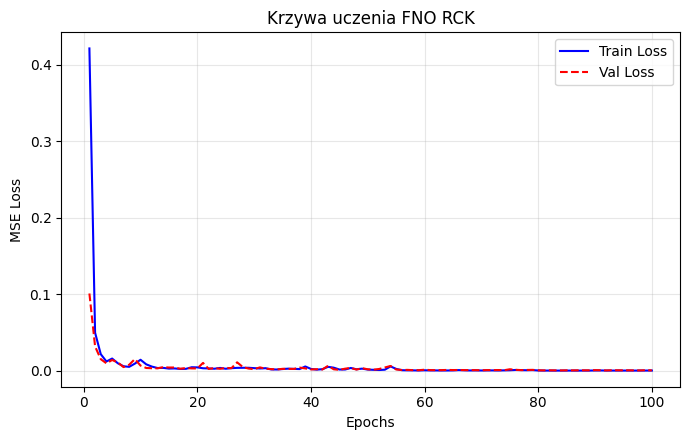

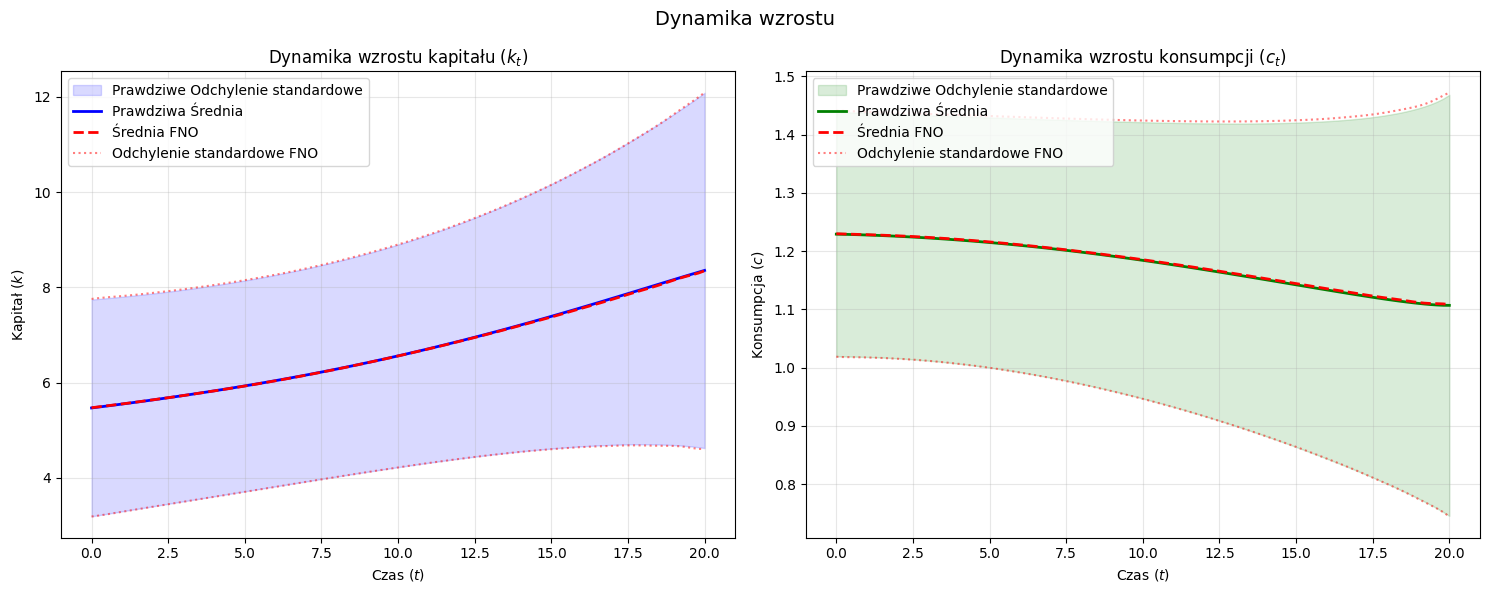

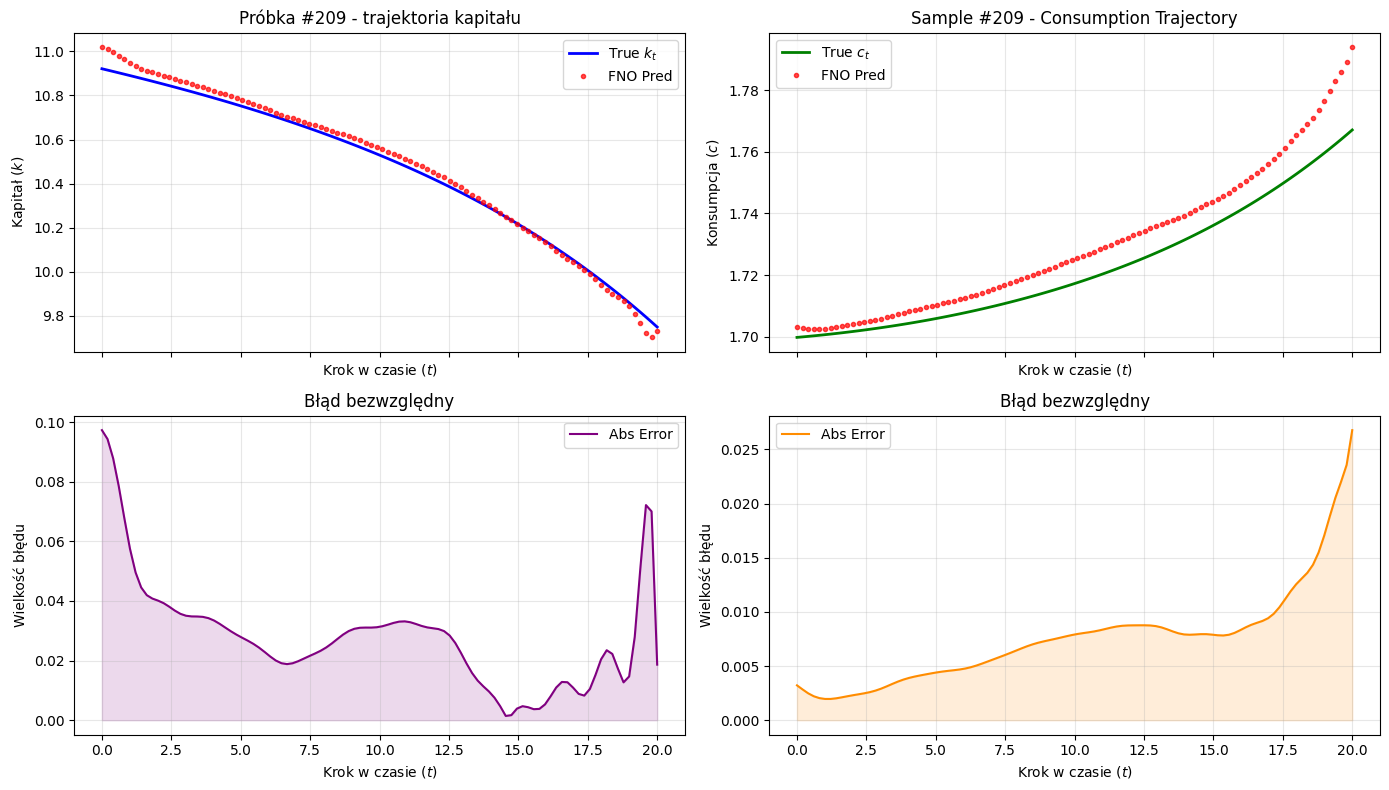

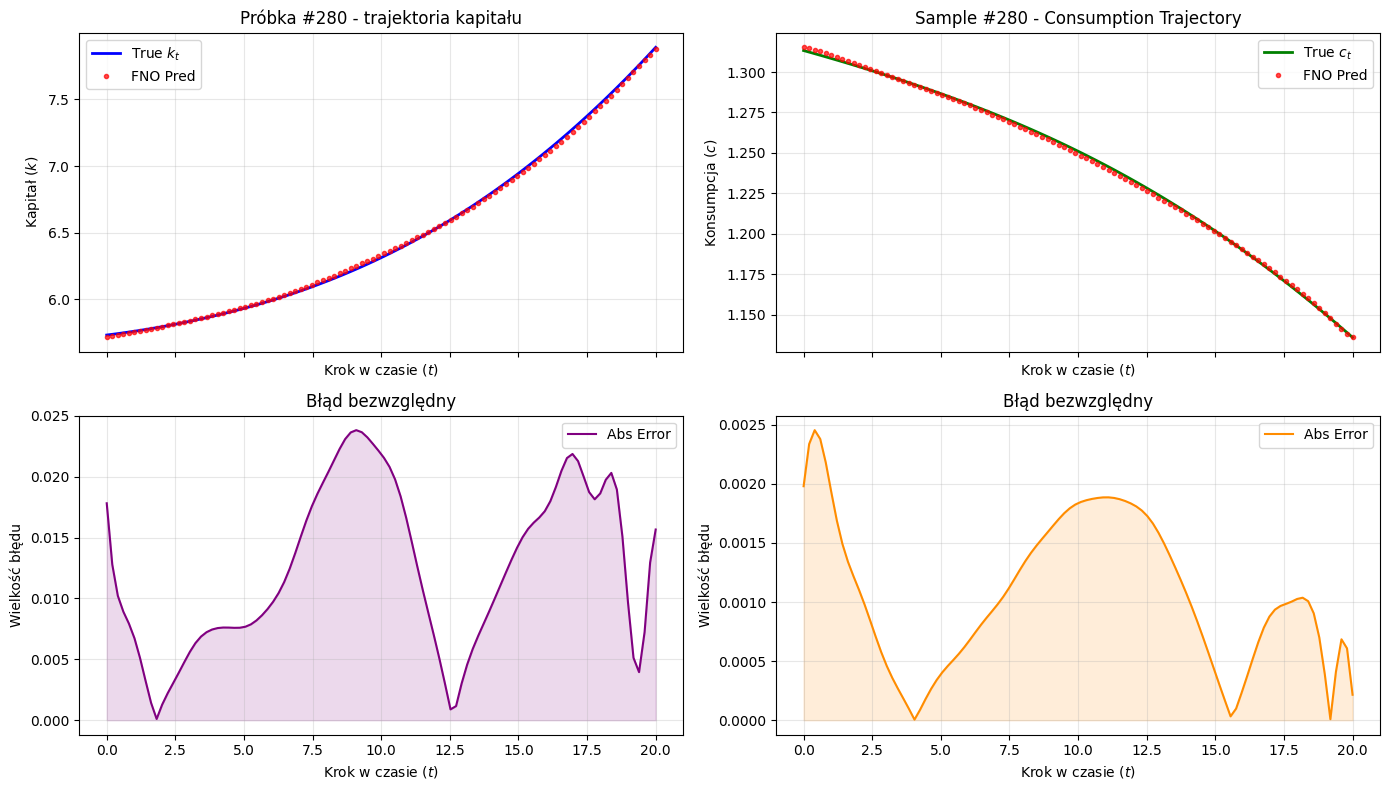

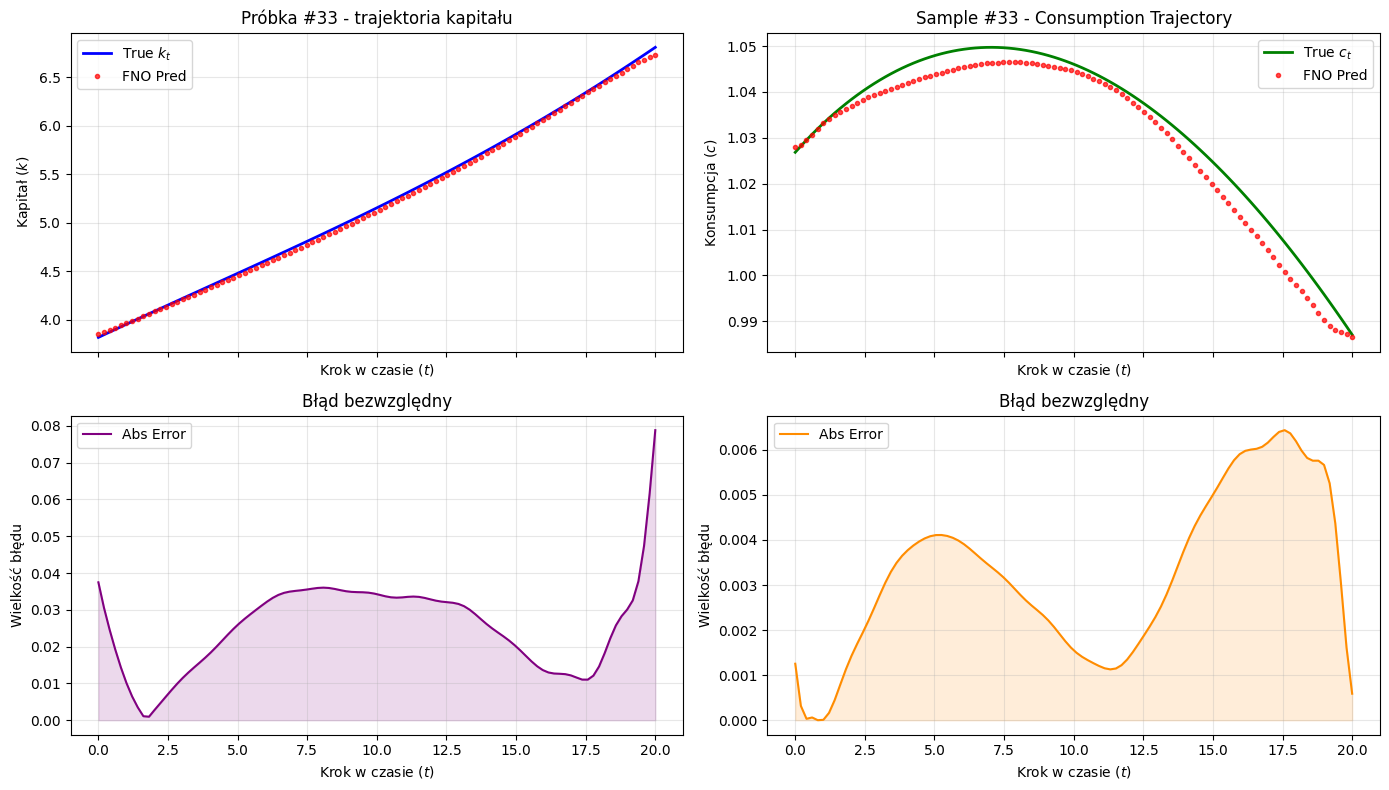

In [15]:
import os
import matplotlib.pyplot as plt
import numpy as np
import torch

# Create an output directory for plots if you want to keep things organized
output_dir = "fno_rck_plots"
os.makedirs(output_dir, exist_ok=True)

# ----------------------------------------------------
# 1. Gather all Predictions and Targets using final_model
# ----------------------------------------------------
final_model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for X_batch, Y_batch in test_loader:
        X_batch = X_batch.permute(0, 2, 1)
        output = final_model(X_batch) # Shape: [Batch, 2, 100]
        
        # Permute back to standard [Batch, Grid, Channels] for scaling ease
        all_preds.append(output.permute(0, 2, 1).numpy())
        all_targets.append(Y_batch.numpy())

all_preds = np.concatenate(all_preds, axis=0)     # Shape: (N_test, 100, 2)
all_targets = np.concatenate(all_targets, axis=0) # Shape: (N_test, 100, 2)

# 2. Invert scaling to view true economic values
# Channel 0 = Capital (k), Channel 1 = Consumption (c)
preds_k = scaler_k.inverse_transform(all_preds[:, :, 0])
preds_c = scaler_c.inverse_transform(all_preds[:, :, 1])

targets_k = scaler_k.inverse_transform(all_targets[:, :, 0])
targets_c = scaler_c.inverse_transform(all_targets[:, :, 1])

# Extract an actual time axis from your data
time_axis = test_data[[f't_grid_{i}' for i in range(grid_size)]].iloc[0].values

# Compute Absolute Errors
abs_error_k = np.abs(targets_k - preds_k)
abs_error_c = np.abs(targets_c - preds_c)

print(f"Data gathered successfully. Saving plots to the '{output_dir}/' folder...")


plt.figure(figsize=(7, 4.5))
plt.plot(range(1, FINAL_EPOCHS + 1), train_losses, label='Train Loss', color='blue', linewidth=1.5)
plt.plot(range(1, FINAL_EPOCHS + 1), val_losses, label='Val Loss', color='red', linestyle='--', linewidth=1.5)
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.title('Krzywa uczenia FNO RCK')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save Plot 1
plot1_path = os.path.join(output_dir, "loss_history_FNO_RCK.png")
plt.savefig(plot1_path, dpi=300, bbox_inches='tight')
plt.show()


mean_target_k, mean_pred_k = targets_k.mean(axis=0), preds_k.mean(axis=0)
mean_target_c, mean_pred_c = targets_c.mean(axis=0), preds_c.mean(axis=0)
std_target_k, std_pred_k   = targets_k.std(axis=0), preds_k.std(axis=0)
std_target_c, std_pred_c   = targets_c.std(axis=0), preds_c.std(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# --- Left Subplot: Capital ---
axes[0].fill_between(time_axis, mean_target_k - std_target_k, mean_target_k + std_target_k, 
                     color='blue', alpha=0.15, label='Prawdziwe Odchylenie standardowe')
axes[0].plot(time_axis, mean_target_k, color='blue', linewidth=2, label='Prawdziwa Średnia')
axes[0].plot(time_axis, mean_pred_k, color='red', linestyle='--', linewidth=2, label='Średnia FNO')
axes[0].plot(time_axis, mean_pred_k + std_pred_k, color='red', linestyle=':', alpha=0.5)
axes[0].plot(time_axis, mean_pred_k - std_pred_k, color='red', linestyle=':', alpha=0.5, label='Odchylenie standardowe FNO')
axes[0].set_title('Dynamika wzrostu kapitału ($k_t$)')
axes[0].set_xlabel('Czas ($t$)')
axes[0].set_ylabel('Kapitał ($k$)')
axes[0].legend(loc='upper left')
axes[0].grid(True, alpha=0.3)

# --- Right Subplot: Consumption ---
axes[1].fill_between(time_axis, mean_target_c - std_target_c, mean_target_c + std_target_c, 
                     color='green', alpha=0.15, label='Prawdziwe Odchylenie standardowe')
axes[1].plot(time_axis, mean_target_c, color='green', linewidth=2, label='Prawdziwa Średnia')
axes[1].plot(time_axis, mean_pred_c, color='red', linestyle='--', linewidth=2, label='Średnia FNO')
axes[1].plot(time_axis, mean_pred_c + std_pred_c, color='red', linestyle=':', alpha=0.5)
axes[1].plot(time_axis, mean_pred_c - std_pred_c, color='red', linestyle=':', alpha=0.5, label='Odchylenie standardowe FNO')
axes[1].set_title('Dynamika wzrostu konsumpcji ($c_t$)')
axes[1].set_xlabel('Czas ($t$)')
axes[1].set_ylabel('Konsumpcja ($c$)')
axes[1].legend(loc='upper left')
axes[1].grid(True, alpha=0.3)

plt.suptitle('Dynamika wzrostu', fontsize=14, y=0.98)
plt.tight_layout()

# Save Plot 2
plot2_path = os.path.join(output_dir, "RCK_FNO_growth_dynamics.png")
plt.savefig(plot2_path, dpi=300, bbox_inches='tight')
plt.show()



np.random.seed(42) 
random_indices = np.random.choice(len(all_preds), size=3, replace=False)

for sample_idx in random_indices:
    fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
    

    # Top Left: Profiles
    axes[0, 0].plot(time_axis, targets_k[sample_idx], 'b-', linewidth=2, label='True $k_t$')
    axes[0, 0].plot(time_axis, preds_k[sample_idx], 'ro', markersize=3, alpha=0.7, label='FNO Pred')
    axes[0, 0].set_title(f'Próbka #{sample_idx} - trajektoria kapitału')
    axes[0, 0].set_ylabel('Kapitał ($k$)')
    axes[0, 0].set_xlabel('Krok w czasie ($t$)')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    
    # Bottom Left: Absolute Error
    axes[1, 0].fill_between(time_axis, abs_error_k[sample_idx], color='purple', alpha=0.15)
    axes[1, 0].plot(time_axis, abs_error_k[sample_idx], color='purple', linewidth=1.5, label='Abs Error')
    axes[1, 0].set_title('Błąd bezwzględny')
    axes[1, 0].set_xlabel('Krok w czasie ($t$)')
    axes[1, 0].set_ylabel('Wielkość błędu')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)
    

    # Top Right: Profiles
    axes[0, 1].plot(time_axis, targets_c[sample_idx], 'g-', linewidth=2, label='True $c_t$')
    axes[0, 1].plot(time_axis, preds_c[sample_idx], 'ro', markersize=3, alpha=0.7, label='FNO Pred')
    axes[0, 1].set_title(f'Sample #{sample_idx} - Consumption Trajectory')
    axes[0, 1].set_ylabel('Konsumpcja ($c$)')
    axes[0, 1].set_xlabel('Krok w czasie ($t$)')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)
    
    # Bottom Right: Absolute Error
    axes[1, 1].fill_between(time_axis, abs_error_c[sample_idx], color='darkorange', alpha=0.15)
    axes[1, 1].plot(time_axis, abs_error_c[sample_idx], color='darkorange', linewidth=1.5, label='Abs Error')
    axes[1, 1].set_title('Błąd bezwzględny')
    axes[1, 1].set_xlabel('Krok w czasie ($t$)')
    axes[1, 1].set_ylabel('Wielkość błędu')
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    # Save a separate plot file for each distinct sample checked
    plot3_path = os.path.join(output_dir, f"3_sample_{sample_idx}_analysis_fno_RCK.png")
    plt.savefig(plot3_path, dpi=300, bbox_inches='tight')
    plt.show()
